In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv(
    r"E:\Projects\SmartHR\Datasets\train.csv"
)

print("Dataset shape:", train.shape)
print("Missing values:")
print(train.isnull().sum())

Dataset shape: (54808, 13)
Missing values:
employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64


Dataset Shape: (54808, 13)

Data Types:


,Data Type
employee_id,int64
department,object
region,object
education,object
gender,object
recruitment_channel,object
no_of_trainings,int64
age,int64
previous_year_rating,float64
length_of_service,int64



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
employee_id,54808.0,NaN,NaN,NaN,39195.830627,22586.581449,1.0,19669.75,39225.5,58730.5,78298.0
department,54808,9,Sales & Marketing,16840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,54808,34,region_2,12343,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,52399,3,Bachelor's,36669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,54808,2,m,38496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
recruitment_channel,54808,3,other,30446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no_of_trainings,54808.0,NaN,NaN,NaN,1.253011,0.609264,1.0,1.0,1.0,1.0,10.0
age,54808.0,NaN,NaN,NaN,34.803915,7.660169,20.0,29.0,33.0,39.0,60.0
previous_year_rating,50684.0,NaN,NaN,NaN,3.329256,1.259993,1.0,3.0,3.0,4.0,5.0
length_of_service,54808.0,NaN,NaN,NaN,5.865512,4.265094,1.0,3.0,5.0,7.0,37.0


,Missing Count,Missing Percentage
education,2409,4.40
previous_year_rating,4124,7.52


Duplicate rows: 0


,Employee Count
is_promoted,
Not Promoted,50140
Promoted,4668



Promotion percentages:


,Percentage
is_promoted,
Not Promoted,91.48
Promoted,8.52


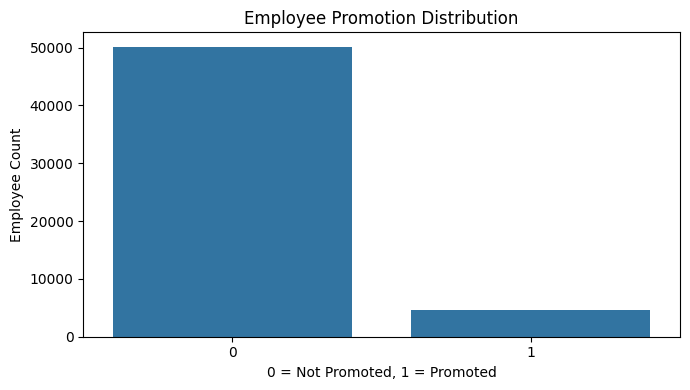

,Promotion Rate (%)
department,
Technology,10.76
Procurement,9.64
Analytics,9.57
Operations,9.01
Finance,8.12
Sales & Marketing,7.20
R&D,6.91
HR,5.62
Legal,5.10


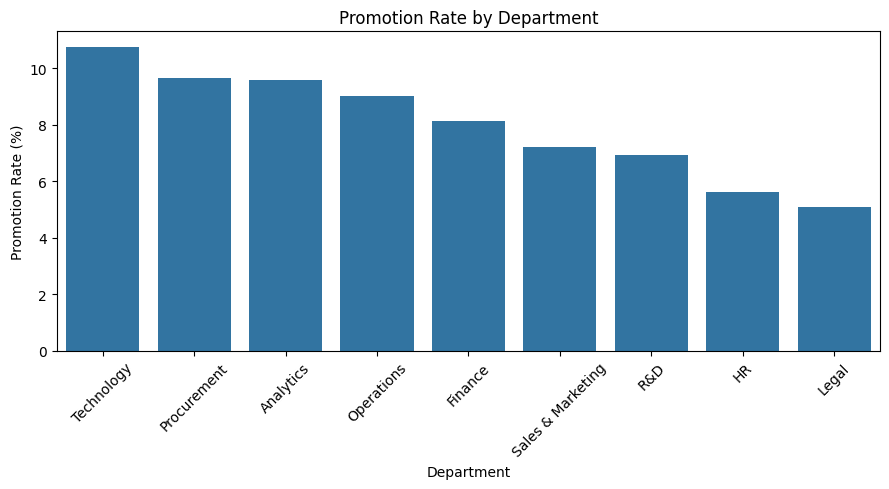

,count,mean,median
is_promoted,,,
0,50140,62.65,60.0
1,4668,71.33,71.0


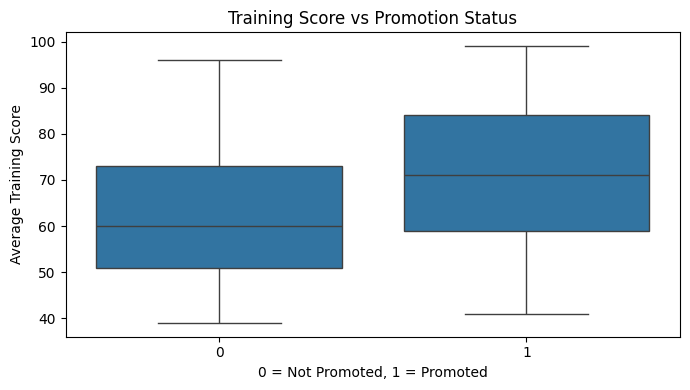

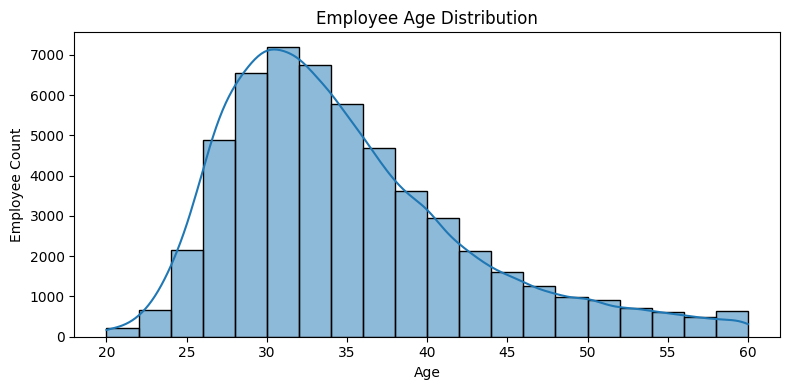

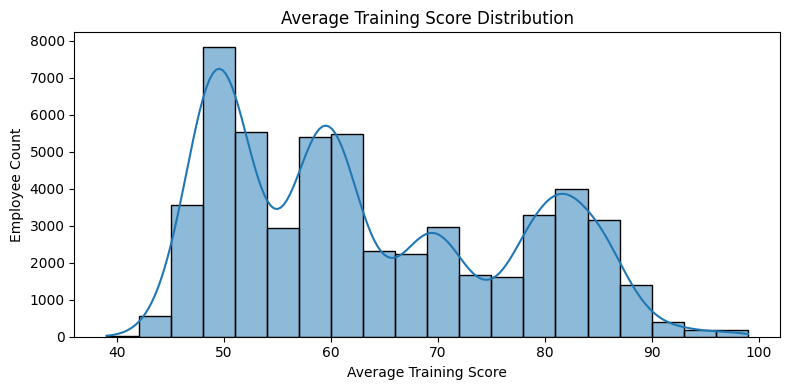

In [2]:

# 1. Dataset overview
print("Dataset Shape:", train.shape)
print("\nData Types:")
display(train.dtypes.to_frame("Data Type"))

print("\nStatistical Summary:")
display(train.describe(include="all").T)

# 2. Missing values
missing_summary = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": (train.isnull().mean() * 100).round(2)
})
display(missing_summary[missing_summary["Missing Count"] > 0])

# 3. Duplicate records
print("Duplicate rows:", train.duplicated().sum())

# 4. Promotion distribution
display(
    train["is_promoted"].value_counts()
    .rename(index={0: "Not Promoted", 1: "Promoted"})
    .to_frame("Employee Count")
)

print("\nPromotion percentages:")
display(
    (train["is_promoted"].value_counts(normalize=True) * 100)
    .rename(index={0: "Not Promoted", 1: "Promoted"})
    .round(2).to_frame("Percentage")
)

plt.figure(figsize=(7, 4))
sns.countplot(data=train, x="is_promoted")
plt.title("Employee Promotion Distribution")
plt.xlabel("0 = Not Promoted, 1 = Promoted")
plt.ylabel("Employee Count")
plt.tight_layout()
plt.show()

# 5. Department-wise promotion rate
dept_rate = (
    train.groupby("department")["is_promoted"]
    .mean().mul(100).sort_values(ascending=False)
)

display(dept_rate.round(2).to_frame("Promotion Rate (%)"))

plt.figure(figsize=(9, 5))
sns.barplot(x=dept_rate.index, y=dept_rate.values)
plt.title("Promotion Rate by Department")
plt.xlabel("Department")
plt.ylabel("Promotion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Training score vs promotion
display(
    train.groupby("is_promoted")["avg_training_score"]
    .agg(["count", "mean", "median"]).round(2)
)

plt.figure(figsize=(7, 4))
sns.boxplot(data=train, x="is_promoted", y="avg_training_score")
plt.title("Training Score vs Promotion Status")
plt.xlabel("0 = Not Promoted, 1 = Promoted")
plt.ylabel("Average Training Score")
plt.tight_layout()
plt.show()

# 7. Age distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=train, x="age", bins=20, kde=True)
plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Employee Count")
plt.tight_layout()
plt.show()

# 8. Training score distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=train, x="avg_training_score", bins=20, kde=True)
plt.title("Average Training Score Distribution")
plt.xlabel("Average Training Score")
plt.ylabel("Employee Count")
plt.tight_layout()
plt.show()


In [3]:

# DATA CLEANING AND EXPORT

# Load original training data
train = pd.read_csv(
    r"E:\Projects\SmartHR\Datasets\train.csv"
)

# Create a separate copy
cleaned = train.copy()

# Remove exact duplicate rows
cleaned = cleaned.drop_duplicates()

# Fill missing education with its mode
education_mode = cleaned["education"].mode()[0]
cleaned["education"] = cleaned["education"].fillna(education_mode)

# Fill missing previous year rating with median
rating_median = cleaned["previous_year_rating"].median()
cleaned["previous_year_rating"] = (
    cleaned["previous_year_rating"].fillna(rating_median)
)

# Verify cleaning
print("Original shape:", train.shape)
print("Cleaned shape:", cleaned.shape)
print("\nMissing values after cleaning:")
print(cleaned.isnull().sum())
print("\nDuplicates:", cleaned.duplicated().sum())

# Save cleaned CSV
cleaned.to_csv(
    r"E:\Projects\SmartHR\Datasets\promotion_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


Original shape: (54808, 13)
Cleaned shape: (54808, 13)

Missing values after cleaning:
employee_id             0
department              0
region                  0
education               0
gender                  0
recruitment_channel     0
no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
awards_won?             0
avg_training_score      0
is_promoted             0
dtype: int64

Duplicates: 0

Cleaned dataset saved successfully!


# Employee Promotion Dataset — EDA Findings

## 1. Dataset Overview
The training dataset contains 54,808 records and 13 columns. The test dataset contains 23,490 records and 12 columns.

## 2. Missing Values
The training dataset contains 2,409 missing values in `education` and 4,124 missing values in `previous_year_rating`.

## 3. Duplicate Records
No exact duplicate rows were found in the training dataset.

## 4. Promotion Distribution
A total of 50,140 employees (91.48%) were not promoted, while 4,668 employees (8.52%) were promoted. This indicates a class imbalance in the target variable.

## 5. Department-wise Promotion
The department-wise graph shows differences in promotion rates. Technology has the highest observed rate, while Legal has the lowest in this dataset.

## 6. Training Score Analysis
The average training score was 62.65 for employees who were not promoted and 71.33 for promoted employees. This suggests an association between training scores and promotion outcomes, but does not establish causation.

## 7. Conclusion
The EDA identified missing values, an imbalanced target variable, and differences in promotion rates across departments. These findings will help guide data preprocessing and further machine-learning analysis.